## Experiment 2: Interacting with Web APIs

**Aim:** To interact with a weather API to retrieve weather data for a specific location and perform data modeling and visualization to analyze weather patterns over time.

In [1]:
# A52 Dipanshu Ambilkar
import requests
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://api.open-meteo.com/v1/forecast"
p = {"latitude": 18.52, "longitude": 73.85, "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation", "forecast_days": 7}
r = requests.get(url, params=p, timeout=30).json()
h = r["hourly"]

In [3]:
df = pd.DataFrame({
    "time": pd.to_datetime(h["time"]),
    "temp": h["temperature_2m"],
    "humidity": h["relative_humidity_2m"],
    "wind": h["wind_speed_10m"],
    "rain": h["precipitation"],
})
print(df.shape)
print(df.isnull().sum())
df = df.dropna()
print("Avg temp:", df["temp"].mean())
print("Max temp:", df["temp"].max(), " Min temp:", df["temp"].min())

(168, 5)
time        0
temp        0
humidity    0
wind        0
rain        0
dtype: int64
Avg temp: 24.54583333333333
Max temp: 30.6  Min temp: 19.1


In [4]:
df["date"] = df["time"].dt.date
daily = df.groupby("date").agg({"temp": "mean", "humidity": "mean", "wind": "mean", "rain": "sum"})
print(daily)

                 temp   humidity      wind  rain
date                                            
2026-11-01  24.645833  77.708333  8.020833   3.0
2026-11-02  23.337500  85.416667  5.700000   5.0
2026-11-03  24.408333  81.458333  4.533333   1.7
2026-11-04  24.075000  82.791667  3.862500   3.3
2026-11-05  25.108333  73.625000  5.654167   0.0
2026-11-06  25.004167  73.500000  8.487500   0.6
2026-11-07  25.241667  64.958333  7.950000   0.0


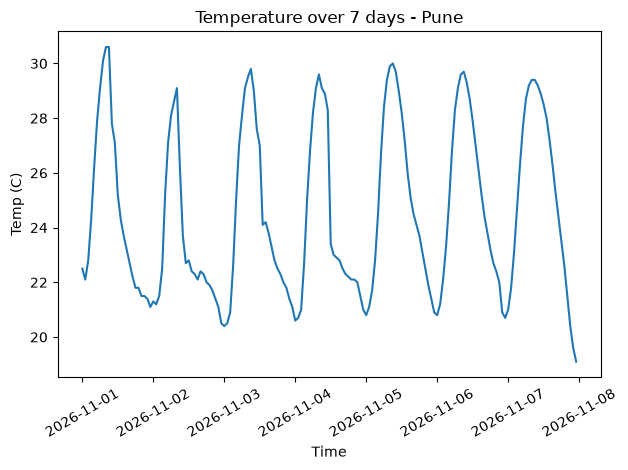

In [5]:
plt.plot(df["time"], df["temp"])
plt.title("Temperature over 7 days - Pune")
plt.xlabel("Time")
plt.ylabel("Temp (C)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

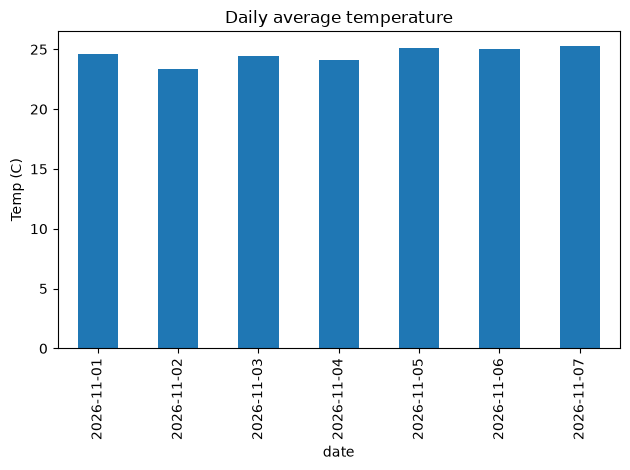

In [6]:
daily["temp"].plot(kind="bar")
plt.title("Daily average temperature")
plt.ylabel("Temp (C)")
plt.tight_layout()
plt.show()

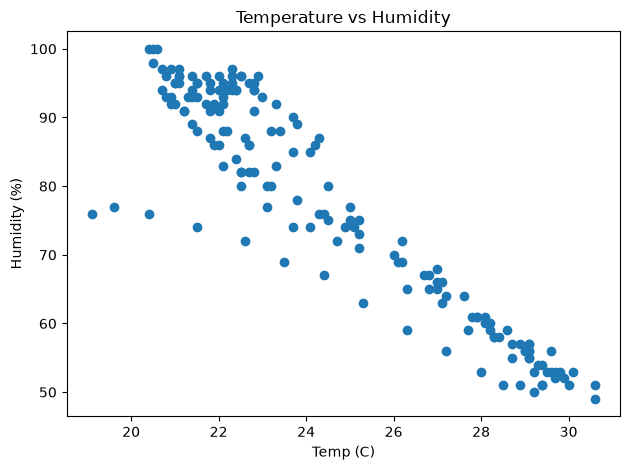

In [7]:
plt.scatter(df["temp"], df["humidity"])
plt.title("Temperature vs Humidity")
plt.xlabel("Temp (C)")
plt.ylabel("Humidity (%)")
plt.tight_layout()
plt.show()

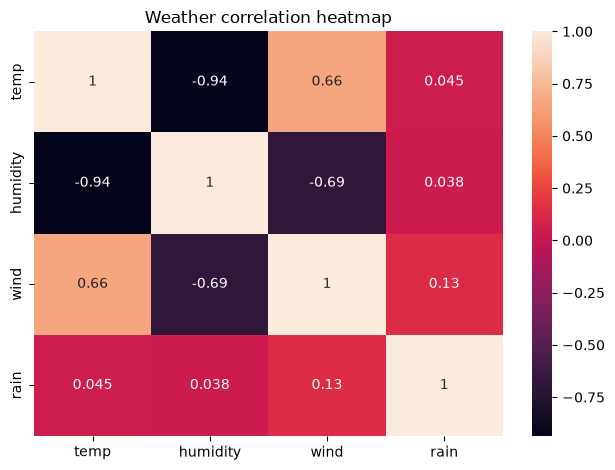

done


In [8]:
sns.heatmap(df[["temp", "humidity", "wind", "rain"]].corr(), annot=True)
plt.title("Weather correlation heatmap")
plt.tight_layout()
plt.show()
print("done")